# Exercise 2 · Fine-tuning DistilBERT trên IMDb

**Mục tiêu.** Huấn luyện bộ phân loại review nhị phân, chọn checkpoint bằng validation và đánh giá sau khi chốt mô hình.

Mở notebook từ thư mục workflow sau khi chạy các lệnh trong [Training.md](Training.md). Các ô dùng dữ liệu của run chỉ định.

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display

RUN = "lan_1"
root = Path.cwd()
run_dir = root / "outputs" / "runs" / RUN

def read(path):
    return json.loads(path.read_text(encoding="utf-8"))

if not (run_dir / "TRAINING_COMPLETE").exists():
    raise FileNotFoundError("Set RUN to a completed run in this workflow.")
configuration = read(run_dir / "config.json")
snapshot = read(run_dir / "split_info.json")
training = configuration["training_arguments"]
validation = read(run_dir / "validation_metrics.json")
print("Run:", RUN, "| device:", configuration["device"])
print("Samples:", {name: item["count"] for name, item in snapshot["splits"].items()})
print("Class counts:", {name: item["label_counts"] for name, item in snapshot["splits"].items()})
print({key: training[key] for key in ("num_train_epochs", "learning_rate", "per_device_train_batch_size")})
print("Max tokens:", snapshot["max_length"])
print("Checkpoint:", configuration["best_checkpoint"])
print("Validation F1:", validation["eval_f1"])

Run: lan_1 | device: cuda:0
Samples: {'train': 2000, 'validation': 400, 'test': 500}
Class counts: {'train': {'NEGATIVE': 1000, 'POSITIVE': 1000}, 'validation': {'NEGATIVE': 200, 'POSITIVE': 200}, 'test': {'NEGATIVE': 250, 'POSITIVE': 250}}
{'num_train_epochs': 3, 'learning_rate': 2e-05, 'per_device_train_batch_size': 8}
Max tokens: 128
Checkpoint: checkpoint-250
Validation F1: 0.8524590163934426


## EDA và đường cong train

train: median=231, p90=596, truncated=89.3%
validation: median=228, p90=560, truncated=89.2%


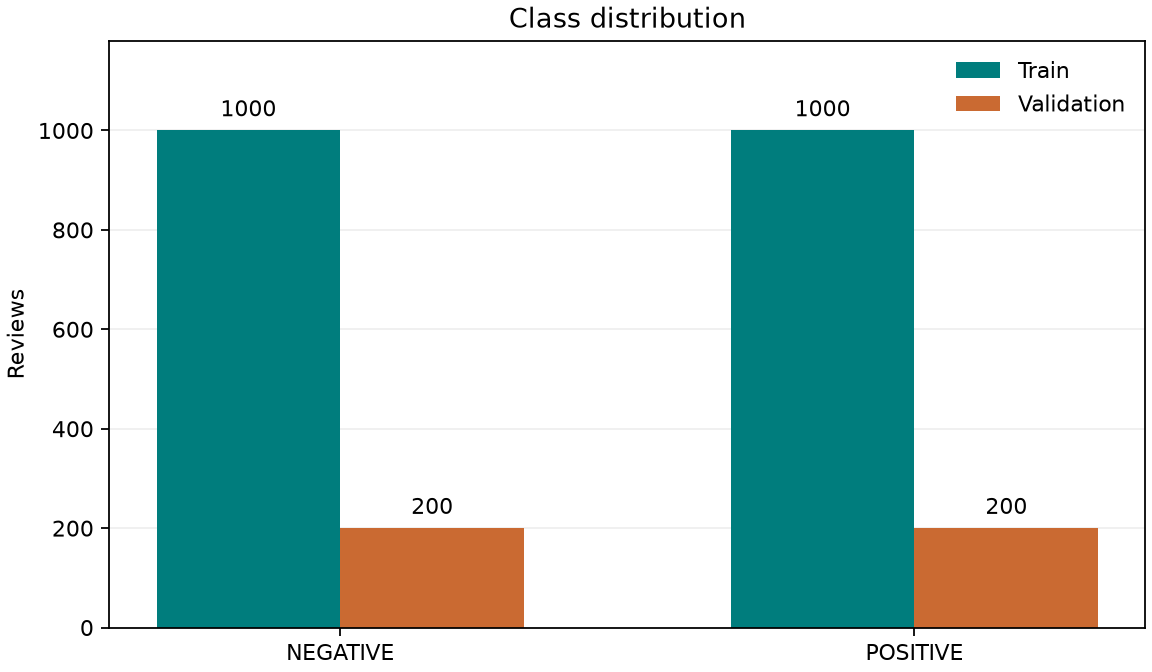

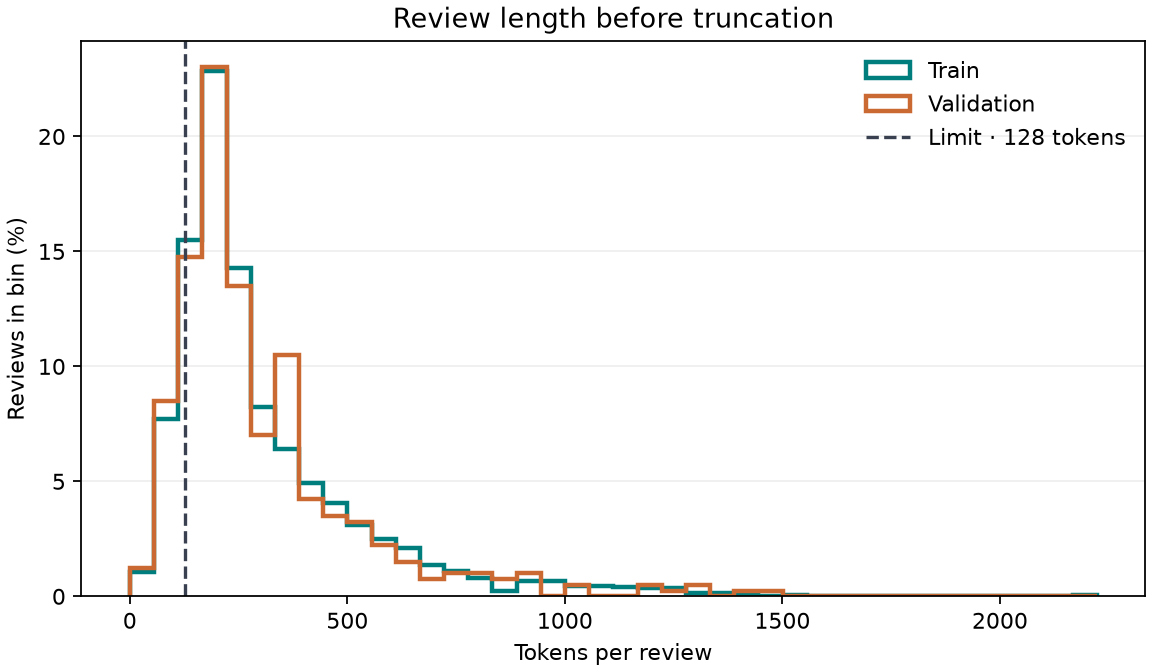

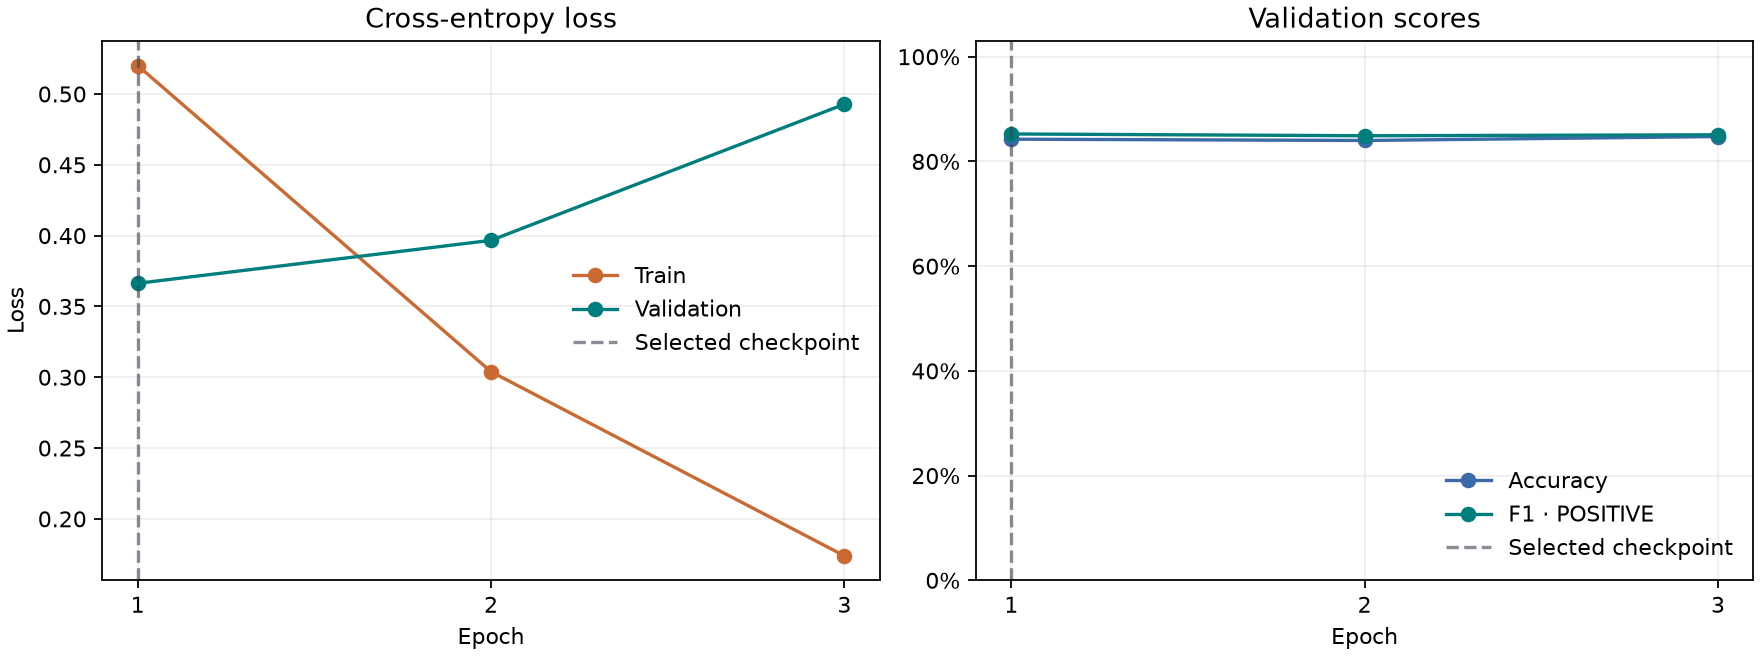

In [2]:
viz = root / "visualization"
eda_path = Path(configuration["data_dir"]) / "eda_summary.json"
if eda_path.is_file():
    eda = read(eda_path)
    for name, stats in eda["splits"].items():
        print(f'{name}: median={stats["median"]:.0f}, p90={stats["p90"]:.0f}, truncated={stats["truncated_fraction"]:.1%}')
    for image in ("label_distribution.png", "token_lengths.png"):
        path = viz / eda["figure_dir"] / image
        if path.is_file():
            display(Image(filename=str(path)))
path = viz / RUN / "training_curves.png"
if path.is_file():
    display(Image(filename=str(path)))

## Đánh giá và phân tích lỗi


Validation · 400 reviews
accuracy: 84.25%
precision: 80.18%
recall: 91.00%
f1: 85.25%


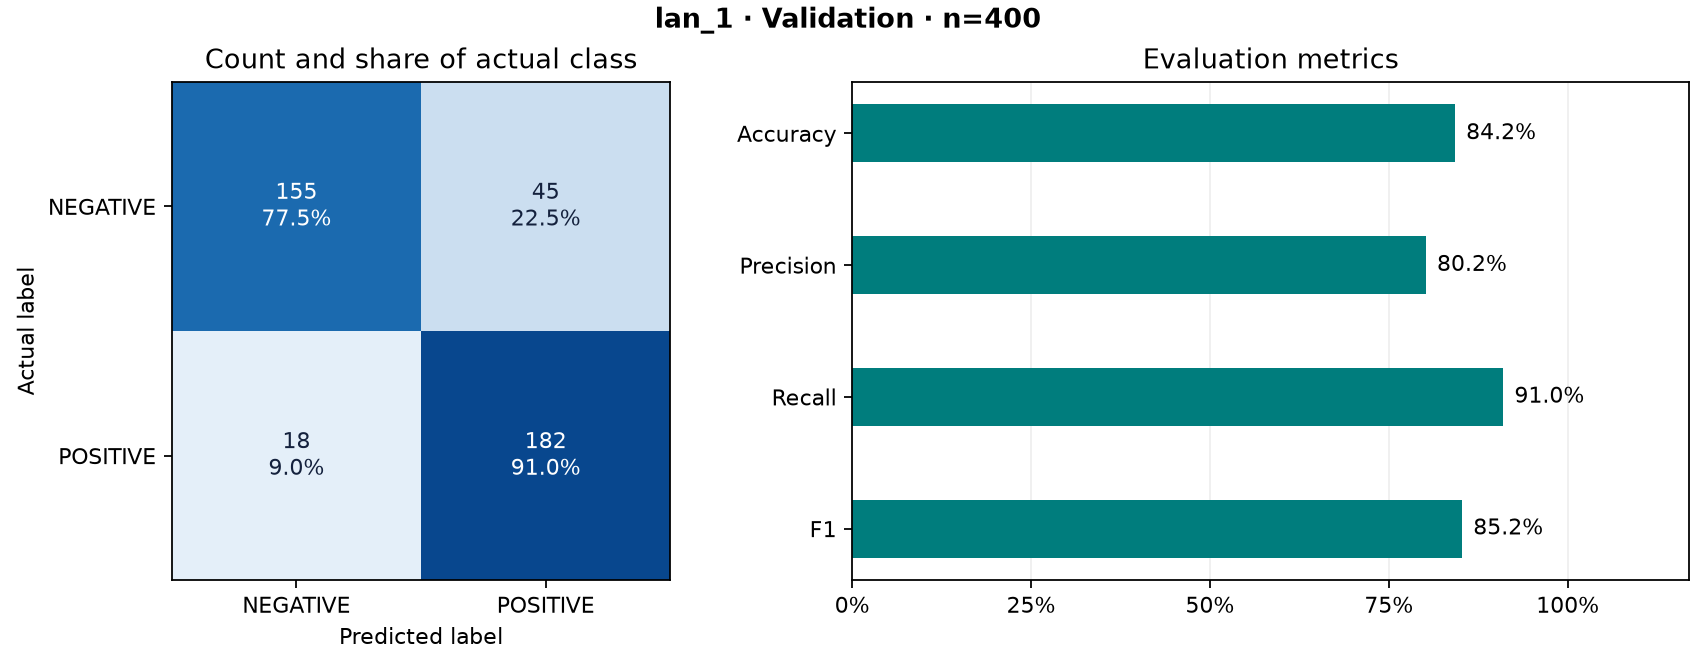

Actual: NEGATIVE | predicted: POSITIVE | score POSITIVE: 95.20%
Don't get me wrong - I love David Suchet as Poirot. I love the series as well as the movies but enough already re: Death On The Nile. Everyone has done this one! We know who dies. We know why they die. We know who the killer is. We know how it was done. So I say enough already! Mr. Suchet could have used that awesome talent in another one of Agatha Christie's novels. I will say that the acting by 
Actual: NEGATIVE | predicted: POSITIVE | score POSITIVE: 93.11%
Well, I finally saw it. I didn't go when it first came out because, well, frankly, I was afraid. Afraid of how bad it might be, or how disappointing. While not as bad as Menace, and better than Clones, it wasn't particularly memorable, or satisfying.<br /><br />I was 11 years old when I saw Star Wars. I still remember sitting in the theater. From the opening crawl to the final credits it was a mov
Actual: NEGATIVE | predicted: POSITIVE | score POSITIVE: 92.94%
"Fredd

In [3]:
for split in ("validation", "test"):
    evidence_path = run_dir / f"{split}_evaluation.json"
    if not evidence_path.is_file():
        print(f"{split.capitalize()} evidence pending.")
        continue
    result = read(evidence_path)
    print(f'\n{split.capitalize()} · {result["sample_count"]} reviews')
    for metric in ("accuracy", "precision", "recall", "f1"):
        print(f'{metric}: {result["metrics"][f"{split}_{metric}"]:.2%}')
    path = viz / RUN / f"{split}_evaluation.png"
    if path.is_file():
        display(Image(filename=str(path)))
    for item in result["error_examples"][:3]:
        print(f'Actual: {item["actual"]} | predicted: {item["predicted"]} | score POSITIVE: {item["probability_positive"]:.2%}')
        print(item["review_excerpt"])

## Nhận xét của nhóm

- Checkpoint được chọn ở epoch nào? Diễn biến validation F1 và validation loss hỗ trợ nhận xét gì?
- Confusion matrix có nhiều false positive hay false negative hơn? Chọn một review dự đoán sai và đọc đoạn trích để xem model có thể đã bỏ qua tín hiệu nào.
- Kết quả phản ánh subset IMDb của run này. Ghi số mẫu và mức truncate khi rút ra kết luận.